[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/johnmarktaylor91/torchlens/blob/main/notebooks/learn/06_gradients.ipynb)

In [1]:
# Colab setup. Does nothing when this notebook runs from a TorchLens checkout
# (learn_models.py is beside it). On Colab there is no checkout, so this installs
# TorchLens from the main branch and fetches learn_models.py next to the notebook.
import pathlib
import shutil
import subprocess
import sys
import urllib.request

if not pathlib.Path("learn_models.py").exists():
    REPO = "johnmarktaylor91/torchlens"
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            f"torchlens[viz] @ git+https://github.com/{REPO}@main",
            "transformers",
            "ipywidgets",
        ],
        check=True,
    )
    if shutil.which("dot") is None:  # drawings need the Graphviz binary
        subprocess.run(["apt-get", "install", "-qq", "-y", "graphviz"], check=True)
    urllib.request.urlretrieve(
        f"https://raw.githubusercontent.com/{REPO}/main/notebooks/learn/learn_models.py",
        "learn_models.py",
    )

# Gradients

**Level 2 of 5. Starting point: what drives this unit?**

Gradients live at the same addresses as activations. One capture option asks TorchLens to keep
them, a backward pass from any scalar fills them in, and `.grad` sits beside `.out` on every
record. The backward graph draws like the forward one, a gradient can be edited like a value, and
the same machinery answers a geometric question: which input pixels can reach a unit at all.

> **You'll want to know:** [reading a record](02_address_and_read.ipynb) (`trace["..."].out`),
> [`capture=tl.options.CaptureOptions(...)`](04_keep_what_you_need.ipynb) (the options object),
> a PyTorch loss and `.backward()` (PyTorch).

In [2]:
import tempfile
from pathlib import Path

import torch
from IPython.display import SVG, display

import torchlens as tl

PICTURES = Path(
    tempfile.mkdtemp(prefix="torchlens_learn_")
)  # drawings land here, not beside the notebook

In [3]:
from learn_models import tiny_cnn, tiny_mlp  # tiny seeded CPU models; nothing downloads

model, x = tiny_mlp()  # two linear layers with a ReLU between them, and a (4, 8) input batch

Ask for gradients, run backward from a scalar, read `.grad` beside `.out`. The ReLU's `.grad` is
the loss sensitivity arriving at its output; what it passes upstream, the gradient at its input
(`linear_1_1`), is masked wherever the activation was zero.


In [4]:
trace = tl.trace(model, x, capture=tl.options.CaptureOptions(save_grads=True))
trace.backward(trace.reconstruct_output().sum())
relu = trace["relu_1_2"]
print("forward          :", relu.out[0, :6].detach())
print("gradient arriving:", relu.grad[0, :6])
print("passed upstream  :", trace["linear_1_1"].grad[0, :6], "(zero where the relu was zero)")

forward          : tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0436, 0.0000])
gradient arriving: tensor([-0.4779, -0.2681, -0.0304, -0.5571, -0.2822, -0.1553])
passed upstream  : tensor([ 0.0000,  0.0000,  0.0000,  0.0000, -0.2822,  0.0000]) (zero where the relu was zero)


## 1. Same addresses, one more option

`save_grads=True` keeps a gradient at every site that has one; a selector keeps only some, exactly
as `save=` did for activations. The trace knows whether a backward pass happened and which sites
hold a gradient. A gradient has the shape of the activation it belongs to.

In [5]:
print(
    "has gradients:",
    trace.autograd.has_grads,
    "| sites with one:",
    list(trace.saved_grad_ops.keys()),
)
print("same shape as the activation:", tuple(relu.grad.shape) == tuple(relu.shape))

relus = tl.trace(model, x, capture=tl.options.CaptureOptions(save_grads=tl.func("relu")))
relus.backward(relus.reconstruct_output().sum())
print("only the relus:", list(relus.saved_grad_ops.keys()))

has gradients: True | sites with one: ['linear_1_1:1', 'relu_1_2:1', 'linear_2_3:1', 'output_1:1']
same shape as the activation: True
only the relus: ['relu_1_2:1']


## 2. A real loss

Any scalar built from `trace.reconstruct_output()` works, so a real loss does. Parameter gradients land where
PyTorch always puts them, on the parameters, and accumulate across backward passes, so start from
a fresh model when you want them clean. The trace lists the trainable parameters it saw.

In [6]:
model, x = tiny_mlp()  # a fresh copy: parameter gradients accumulate in PyTorch
target = torch.tensor([0, 1, 2, 3])
trained = tl.trace(model, x, capture=tl.options.CaptureOptions(save_grads=True))
loss = torch.nn.functional.cross_entropy(trained.reconstruct_output(), target)
trained.backward(loss)
print(f"loss {loss.item():.3f} |", len(trained.params.trainable), "trainable parameter tensors")
print("d loss / d hidden, item 0       :", trained["relu_1_2"].grad[0, :4])
print("d loss / d out_proj.weight, row 0:", model.out_proj.weight.grad[0, :4])
print(
    "d loss / d in_proj.weight, row 0 :",
    model.in_proj.weight.grad[0, :4],
    "(hidden unit 0 is inactive on this batch)",
)

loss 1.481 | 4 trainable parameter tensors
d loss / d hidden, item 0       : tensor([ 0.0308,  0.0117, -0.0446, -0.0380])
d loss / d out_proj.weight, row 0: tensor([0.0000, 0.0000, 0.0166, 0.0316])
d loss / d in_proj.weight, row 0 : tensor([0., 0., 0., 0.]) (hidden unit 0 is inactive on this batch)


## 3. The backward graph

The backward pass is a graph too: autograd's nodes as they ran, which include the loss, the
transposes and the accumulation into each parameter, so there are more of them than forward
ops. `trace.draw(graph="backward")` draws it, `trace.draw(graph="combined")` draws it next to the forward graph.


12 grad_fn nodes recorded


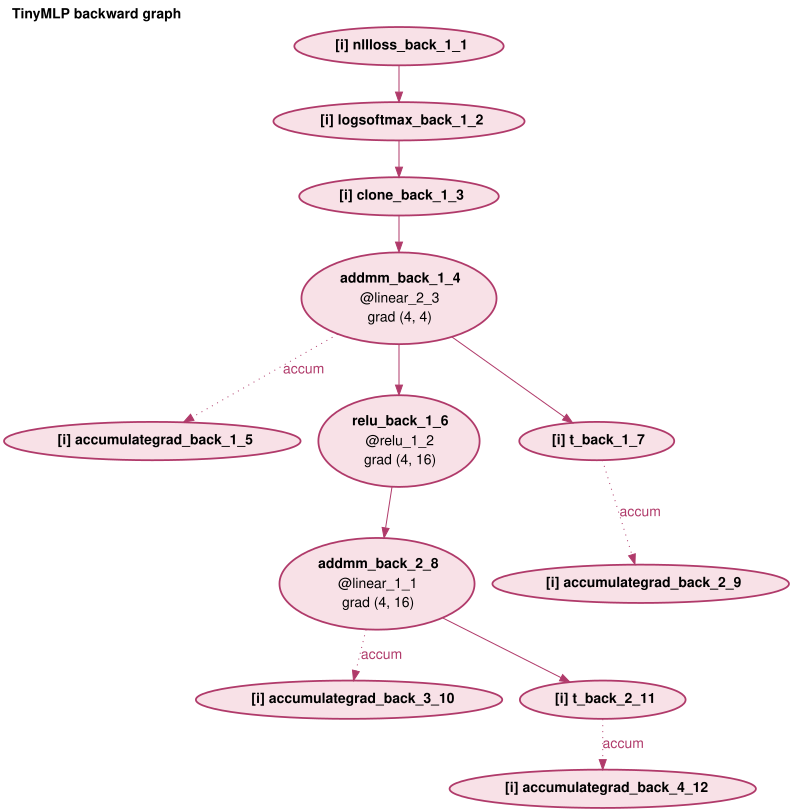

In [7]:
print(len(trained.autograd.grad_fns), "grad_fn nodes recorded")
trained.draw(graph="backward", path=str(PICTURES / "mlp_backward"), file_format="svg")
SVG(filename=PICTURES / "mlp_backward.svg")  # draw(graph="backward") writes the file; this shows it

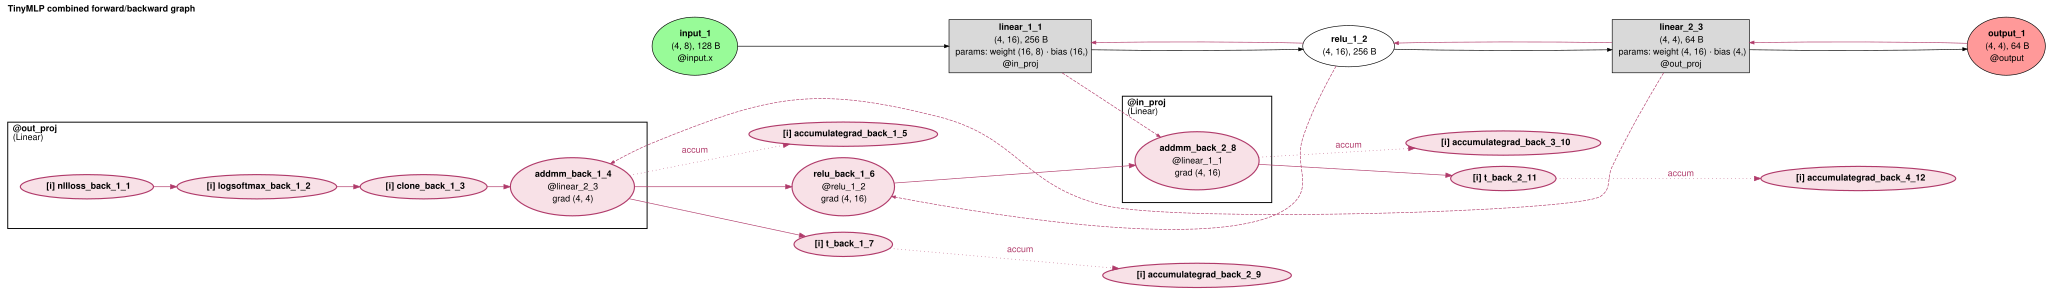

In [8]:
trained.draw(graph="combined", path=str(PICTURES / "mlp_combined"), file_format="svg")
SVG(filename=PICTURES / "mlp_combined.svg")

## 4. Edit a gradient

`intervene=` reaches the backward pass with the same `tl.when(where, what)`: `tl.grad(site)`
names the gradient of a site's output, and any ordinary edit applies to it (`tl.zero_ablate()`,
`tl.scale(f)`, `tl.clamp(low=..., high=...)`). The edit replaces the gradient at the site on its
way upstream, and the record shows the edited gradient. Here the ReLU's output gradient is zeroed,
which in this MLP blocks the gradient to the first layer's weights and leaves the second layer's
unchanged.

In [9]:
model, x = tiny_mlp()
blocked = tl.trace(
    model,
    x,
    capture=tl.options.CaptureOptions(save_grads=True),
    intervene=tl.when(tl.grad(tl.func("relu")), tl.zero_ablate()),
)
blocked.backward(torch.nn.functional.cross_entropy(blocked.reconstruct_output(), target))
print("gradient at the relu, edited:", blocked["relu_1_2"].grad[0, :4])
print("in_proj.weight.grad is zero :", bool((model.in_proj.weight.grad == 0).all()))
print("out_proj.weight.grad is zero:", bool((model.out_proj.weight.grad == 0).all()))

gradient at the relu, edited: tensor([0., 0., 0., 0.])
in_proj.weight.grad is zero : True
out_proj.weight.grad is zero: False


## 5. A taste of receptive fields

A gradient says how much an input mattered for one run. A receptive field says which inputs could
matter at all, read from the graph's geometry rather than from any values. Every record carries
one; for a convolutional model it is a window on the input image that grows with depth, and
`rf.at(unit)` gives the exact pixel box one output unit can see.

In [10]:
cnn, image = tiny_cnn()  # six conv blocks of 3x3 convs on a 16x16 image
big = tl.trace(cnn, image)
for address in ["stem", "blocks.0", "blocks.2", "blocks.5"]:
    rf = big[address].receptive_field  # a Module; it ran once, so one field
    print(f"{address:>9}: a {rf.size} window on the input, status {rf.status.name}")

box = big["blocks.2"].receptive_field.at((8, 8))  # which input pixels reach output unit (8, 8)
for axis in box.axes[-2:]:  # the two spatial axes of the (batch, channel, height, width) input
    print(f"input axis {axis.input_axis}: pixels {axis.clipped_start} to {axis.clipped_stop}")

     stem: a (3, 3) window on the input, status EXACT
 blocks.0: a (5, 5) window on the input, status EXACT
 blocks.2: a (9, 9) window on the input, status EXACT
 blocks.5: a (15, 15) window on the input, status EXACT
input axis 2: pixels 4 to 13
input axis 3: pixels 4 to 13


## 6. That was the backward side of level 2

`CaptureOptions(save_grads=...)` keeps gradients at the addresses you already use,
`trace.backward(scalar)` fills them, `trace.draw(graph="backward")` draws them, `tl.when(tl.grad(site), edit)` edits them, and
`op.receptive_field` answers the geometric question without any values at all.

**One thing about networks:** `.grad` at the ReLU's output is what the loss sends back, and the
ReLU passes it on to its input only where the activation was positive; that is why the first
layer's gradient has zeros where the hidden values were zero. A unit that is zero for a whole
batch gets no update from that batch.

**Go deeper:** next is [07, Compare runs](07_compare_runs.ipynb). The workflow for receptive
fields is [iou_heatmap](../../examples/workflows/iou_heatmap.ipynb). Reference: the glossary's
"Backward helpers" and "Receptive field / Projective field" entries in
[glossary.md](../../docs/reference/glossary.md).